In [1]:
# importing data set
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 140)

RAW = {
    "kaub_level":   "../data/raw/water_level_15min_kaub.csv",
    "bingen_level": "../data/raw/bingen_water_level15_min.csv",
    "discharge":    "../data/raw/kaub_water_discharge.csv",
}
WEATHER_HOURLY = "../data/processed/kaub_water_weather_hourly.csv"
WEATHER_DAILY  = "../data/processed/kaub_water_weather_daily.csv"

OUT_HOURLY = "../data/processed/kaub_hydro_weather_hourly.csv"
OUT_DAILY  = "../data/processed/kaub_hydro_weather_daily.csv"

In [2]:
def load_raw(path: str, name: str) -> pd.Series:
    """Load and clean raw 15-minute water-level data from WSV."""

    # Read the raw CSV file using a semicolon as the separator
    d = pd.read_csv(path, sep=";")

    # Convert timestamps to datetime format
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # Convert water-level values to numeric and replace invalid values with NaN
    d["value"] = pd.to_numeric(d["value"], errors="coerce")

    # Generate a data quality report before removing duplicates
    report = {
        "rows": len(d),
        "duplicate timestamps": int(d["timestamp"].duplicated().sum()),
        "non-numeric values": int(d["value"].isna().sum()),
        "first": d["timestamp"].min(),
        "last": d["timestamp"].max(),
    }

    # Handle duplicate timestamps by calculating their mean water level
    # Sort chronologically and assign the station name to the Series
    s = d.groupby("timestamp")["value"].mean().sort_index().rename(name)

    # Record the number of observations after removing duplicate timestamps
    report["rows after dedup"] = len(s)

    # Display the data quality report for each station
    print(f"--- {name} ---")
    for k, v in report.items():
        print(f"  {k:22s}: {v}")

    # Return the cleaned water-level time series
    return s


# Load and clean raw water-level data for all stations defined in RAW
# Store the cleaned time series in a dictionary using station names as keys
series = {name: load_raw(path, name) for name, path in RAW.items()}

--- kaub_level ---
  rows                  : 935128
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-01 23:45:00
  rows after dedup      : 935024
--- bingen_level ---
  rows                  : 936714
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-18 12:15:00
  rows after dedup      : 936610
--- discharge ---
  rows                  : 936713
  duplicate timestamps  : 104
  non-numeric values    : 0
  first                 : 2000-01-01 01:00:00
  last                  : 2026-09-18 12:00:00
  rows after dedup      : 936609


In [3]:
# Create a dictionary to store duplicate timestamp information for each station
dup_check = {}

# Loop through all stations and their corresponding raw data files
for name, path in RAW.items():

    # Read the raw CSV file using a semicolon as the separator
    d = pd.read_csv(path, sep=";")

    # Convert timestamps to datetime format
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    # Identify all rows with duplicate timestamps, including their first occurrence
    dups = d.loc[d["timestamp"].duplicated(keep=False), "timestamp"]

    # Summarize duplicate timestamp information for each station
    dup_check[name] = {

        # Count the total number of rows involved in duplicate timestamps
        "n duplicated rows": len(dups),

        # Count the number of unique dates affected by duplicate timestamps
        "distinct dates affected": dups.dt.date.nunique(),

        # Identify the months in which duplicate timestamps occur
        "months affected": sorted(dups.dt.month.unique().tolist()),

        # Identify the hours in which duplicate timestamps occur
        "hours affected": sorted(dups.dt.hour.unique().tolist()),

    }

# Convert the duplicate summary into a DataFrame for comparison across stations
pd.DataFrame(dup_check).T

,n duplicated rows,distinct dates affected,months affected,hours affected
kaub_level,208,26,[10],[2]
bingen_level,208,26,[10],[2]
discharge,208,26,[10],[2]


In [4]:
# Load the processed daily hydro-weather dataset
final_merged_df = pd.read_csv(
    "../data/processed/kaub_hydro_weather_daily.csv"
)

# Identify all numeric columns in the dataset
numeric_cols = final_merged_df.select_dtypes(include="number").columns

# Round numeric values to the nearest integer
# Convert them to nullable integers (Int64) to preserve missing values
final_merged_df[numeric_cols] = (
    final_merged_df[numeric_cols]
    .round()
    .astype("Int64")
)

# Display the first five rows of the updated dataset
final_merged_df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [5]:
#final merged data
final_merged_df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [6]:
#assigned to df 
df = final_merged_df

In [7]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])

# Select all numeric columns
#numeric_cols = df.select_dtypes(include="number").columns

# Round values and convert to integers
#df[numeric_cols] = df[numeric_cols].round(0).astype("Int64")

# Sort by date
df = df.sort_values("date").reset_index(drop=True)

# Display the DataFrame
df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean,bingen_level_mean,bingen_level_min,bingen_level_max,discharge_mean,discharge_min,discharge_max,hours_available
0,2000-01-01,439,421,458,3,97,2,2,0,1025,8,359,346,373,3274,3128,3432,23
1,2000-01-02,401,385,419,4,96,0,0,0,1030,6,333,322,345,2970,2842,3110,24
2,2000-01-03,368,359,384,2,94,0,0,0,1028,12,311,306,320,2707,2640,2825,24
3,2000-01-04,346,337,359,5,92,1,1,0,1020,18,295,290,304,2535,2460,2638,24
4,2000-01-05,328,320,337,5,90,0,0,0,1022,10,282,276,289,2394,2330,2460,24


In [8]:
# Count the number of days for each recorded number of available hourly observations
# Sort the results by the number of hours to identify days with missing or extra observations
df["hours_available"].value_counts().sort_index()

hours_available
23      28
24    9713
Name: count, dtype: Int64

In [9]:
# Select the main hydrological variables for correlation analysis
cols = [
    "water_level_mean",
    "bingen_level_mean",
    "discharge_mean"
]

# Calculate the Pearson correlation coefficients between the selected variables
# Identify the strength and direction of their linear relationships
df[cols].corr()

,water_level_mean,bingen_level_mean,discharge_mean
water_level_mean,1.000000,0.999100,0.995367
bingen_level_mean,0.999100,1.000000,0.992492
discharge_mean,0.995367,0.992492,1.000000


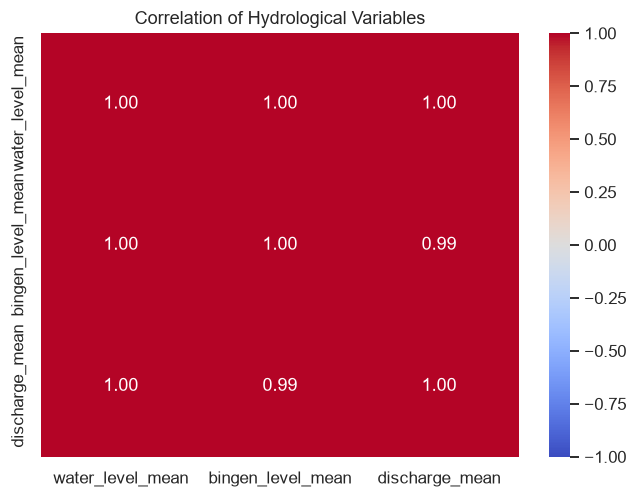

In [10]:
# Import libraries for data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size for the correlation heatmap
plt.figure(figsize=(7, 5))

# Create a heatmap to visualize correlations between hydrological variables
sns.heatmap(
    df[cols].corr(),  # Calculate Pearson correlation coefficients
    annot=True,       # Display correlation values inside each cell
    fmt=".2f",        # Show correlation values with two decimal places
    cmap="coolwarm",  # Use a color gradient to represent correlation strength
    vmin=-1,          # Set the minimum correlation value
    vmax=1            # Set the maximum correlation value
)

# Add a descriptive title to the heatmap
plt.title("Correlation of Hydrological Variables")

# Display the correlation heatmap
plt.show()

In [11]:
# Calculate the correlation between Kaub water levels and lagged Bingen water levels
# Test lags from 0 to 7 days to examine the upstream-downstream relationship
for lag in range(0, 8):

    # Shift Bingen water levels by the specified number of days
    # Calculate the Pearson correlation with Kaub water levels
    corr = df["water_level_mean"].corr(
        df["bingen_level_mean"].shift(lag)
    )

    # Display the correlation coefficient for each lag
    print(f"Bingen lag {lag}: r = {corr:.3f}")

Bingen lag 0: r = 0.999
Bingen lag 1: r = 0.985
Bingen lag 2: r = 0.945
Bingen lag 3: r = 0.895
Bingen lag 4: r = 0.846
Bingen lag 5: r = 0.800
Bingen lag 6: r = 0.759
Bingen lag 7: r = 0.722


In [12]:
# Calculate the correlation between Kaub water levels and lagged discharge values
# Test lags from 0 to 7 days to examine their temporal relationship
for lag in range(0, 8):

    # Shift discharge values by the specified number of days
    # Calculate the Pearson correlation with Kaub water levels
    corr = df["water_level_mean"].corr(
        df["discharge_mean"].shift(lag)
    )

    # Display the correlation coefficient for each lag
    print(f"Discharge lag {lag}: r = {corr:.3f}")

Discharge lag 0: r = 0.995
Discharge lag 1: r = 0.977
Discharge lag 2: r = 0.934
Discharge lag 3: r = 0.881
Discharge lag 4: r = 0.829
Discharge lag 5: r = 0.782
Discharge lag 6: r = 0.740
Discharge lag 7: r = 0.702


In [13]:
# Calculate cumulative precipitation over different time windows
# Rolling sums capture the effect of recent rainfall on river water levels

# Calculate total precipitation over the current and previous 2 days
df["precip_3d"] = df["precipitation_sum"].rolling(3).sum()

# Calculate total precipitation over the current and previous 6 days
df["precip_7d"] = df["precipitation_sum"].rolling(7).sum()

# Calculate total precipitation over the current and previous 13 days
df["precip_14d"] = df["precipitation_sum"].rolling(14).sum()

# Calculate total precipitation over the current and previous 29 days
df["precip_30d"] = df["precipitation_sum"].rolling(30).sum()

In [14]:
# Calculate the correlation between water levels and cumulative precipitation over different time windows
# Identify which rainfall period has the strongest linear relationship with Kaub water levels

rain_cols = [
    "precipitation_sum",
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d"
]

df[rain_cols + ["water_level_mean"]].corr()["water_level_mean"]

precipitation_sum    0.059607
precip_3d            0.181170
precip_7d            0.390553
precip_14d           0.490115
precip_30d           0.524351
water_level_mean     1.000000
Name: water_level_mean, dtype: float64

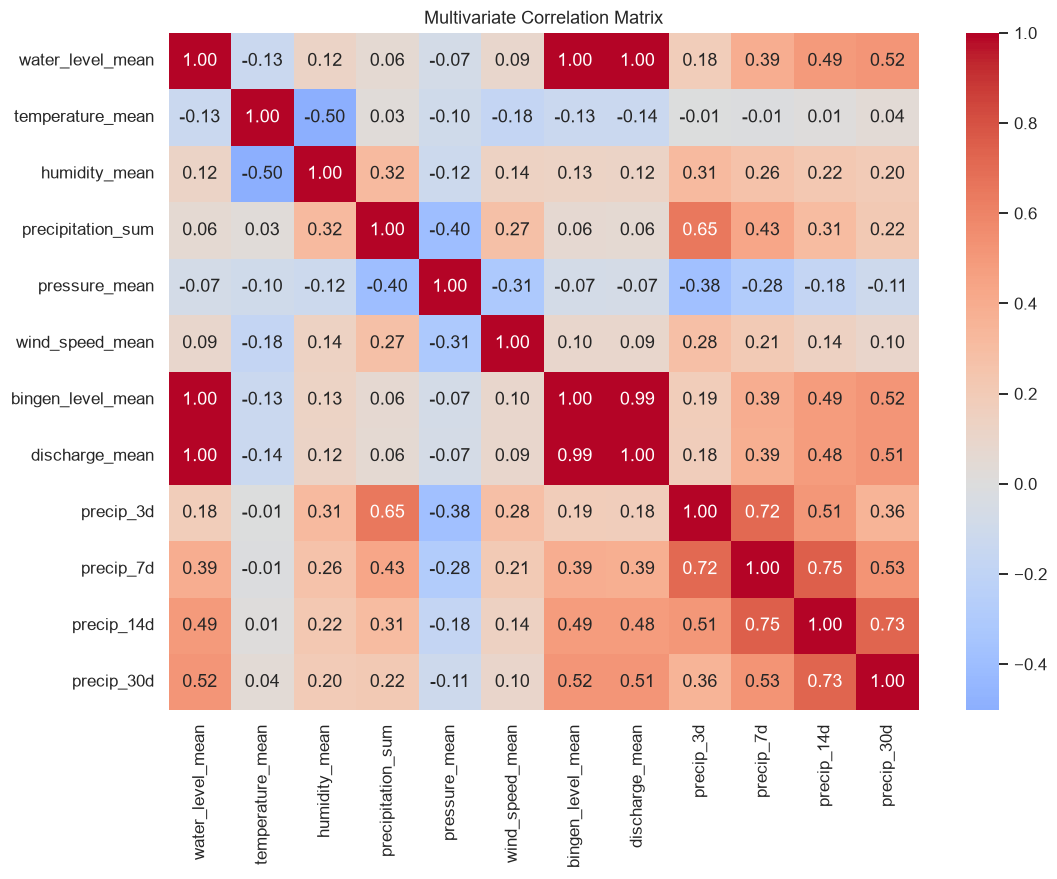

In [15]:
# Visualize the correlations among hydrological and weather variables
# Identify relationships with water levels and potential multicollinearity among features

features = [
    "water_level_mean",
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "pressure_mean",
    "wind_speed_mean",
    "bingen_level_mean",
    "discharge_mean",
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d"
]

plt.figure(figsize=(11, 8))

sns.heatmap(
    df[features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Multivariate Correlation Matrix")

plt.show()

In [16]:
#Fixing the target feature
TARGET = "water_level_mean"

In [17]:
# Kaub water-level lags
df["level_lag_1"] = df["water_level_mean"].shift(1)
df["level_lag_2"] = df["water_level_mean"].shift(2)
df["level_lag_3"] = df["water_level_mean"].shift(3)
df["level_lag_7"] = df["water_level_mean"].shift(7)
df["level_lag_14"] = df["water_level_mean"].shift(14)

In [18]:
# Calculate the daily change in Kaub water level compared to the previous day

df["level_change_1d"] = df["water_level_mean"].diff(1)

In [19]:
# Create lagged Bingen water-level features for the previous 1, 2, and 3 days
# Capture the influence of historical upstream water levels on Kaub

df["bingen_lag_1"] = df["bingen_level_mean"].shift(1)

df["bingen_lag_2"] = df["bingen_level_mean"].shift(2)

df["bingen_lag_3"] = df["bingen_level_mean"].shift(3)

In [20]:
# Create lagged discharge features for the previous 1, 2, and 3 days
# Capture the influence of historical river discharge on Kaub water levels

df["discharge_lag_1"] = df["discharge_mean"].shift(1)

df["discharge_lag_2"] = df["discharge_mean"].shift(2)

df["discharge_lag_3"] = df["discharge_mean"].shift(3)

In [21]:
# Calculate the daily change in river discharge compared to the previous day

df["discharge_change_1d"] = df["discharge_mean"].diff(1)

In [22]:
# Calculate cumulative precipitation over 3, 7, 14, and 30 days
# Capture the influence of recent rainfall on river water levels

df["precip_3d"] = df["precipitation_sum"].rolling(3).sum()

df["precip_7d"] = df["precipitation_sum"].rolling(7).sum()

df["precip_14d"] = df["precipitation_sum"].rolling(14).sum()

df["precip_30d"] = df["precipitation_sum"].rolling(30).sum()

In [23]:
# Calculate the average temperature over 3 and 7 days
# Capture short-term temperature trends that may influence river water levels

df["temp_3d"] = df["temperature_mean"].rolling(3).mean()

df["temp_7d"] = df["temperature_mean"].rolling(7).mean()

In [24]:
# Create cyclical day-of-year features using sine and cosine transformations
# Capture seasonal patterns while preserving the continuity between the end and start of each year

import numpy as np

df["day_of_year"] = df["date"].dt.dayofyear

df["doy_sin"] = np.sin(
    2 * np.pi * df["day_of_year"] / 365.25
)

df["doy_cos"] = np.cos(
    2 * np.pi * df["day_of_year"] / 365.25
)

In [25]:
# Create target variables for forecasting Kaub water levels from 1 to 7 days ahead
# Shift water levels backward to align each future target with the current day's features

for h in range(1, 8):

    df[f"target_day_{h}"] = df["water_level_mean"].shift(-h)

In [26]:
# Define the input features for multivariate water-level forecasting
# Include historical river conditions, weather patterns, and seasonal variations

FEATURES = [
    # Kaub history
    "level_lag_1",
    "level_lag_2",
    "level_lag_3",
    "level_lag_7",
    "level_lag_14",
    "level_change_1d",

    # Upstream Bingen
    "bingen_lag_1",
    "bingen_lag_2",
    "bingen_lag_3",

    # Discharge
    "discharge_lag_1",
    "discharge_lag_2",
    "discharge_lag_3",
    "discharge_change_1d",

    # Rainfall memory
    "precip_3d",
    "precip_7d",
    "precip_14d",
    "precip_30d",

    # Temperature
    "temp_3d",
    "temp_7d",

    # Seasonality
    "doy_sin",
    "doy_cos"
]

In [27]:
# Define the target columns for predicting Kaub water levels from 1 to 7 days ahead

Target_cols = [
    f"target_day_{h}"
    for h in range(1, 8)
]

In [28]:
# Calculate correlations between input features and future water levels for all seven forecast horizons
# Identify how the linear relationship between each feature and the target changes over time

TARGETS = [
    f"target_day_{h}"
    for h in range(1, 8)
]

corr_horizons = df[
    FEATURES + TARGETS
].corr().loc[FEATURES, TARGETS]

display(corr_horizons.round(3))

,target_day_1,target_day_2,target_day_3,target_day_4,target_day_5,target_day_6,target_day_7
level_lag_1,0.941,0.890,0.840,0.794,0.753,0.716,0.684
level_lag_2,0.890,0.840,0.794,0.753,0.716,0.684,0.655
level_lag_3,0.840,0.794,0.753,0.716,0.684,0.655,0.631
level_lag_7,0.684,0.655,0.631,0.611,0.594,0.580,0.567
level_lag_14,0.555,0.544,0.533,0.523,0.514,0.505,0.494
level_change_1d,0.223,0.269,0.267,0.244,0.218,0.194,0.173
bingen_lag_1,0.945,0.895,0.846,0.800,0.759,0.722,0.690
bingen_lag_2,0.895,0.846,0.800,0.759,0.722,0.690,0.661
bingen_lag_3,0.846,0.800,0.759,0.722,0.690,0.661,0.636
discharge_lag_1,0.934,0.881,0.829,0.782,0.740,0.702,0.669


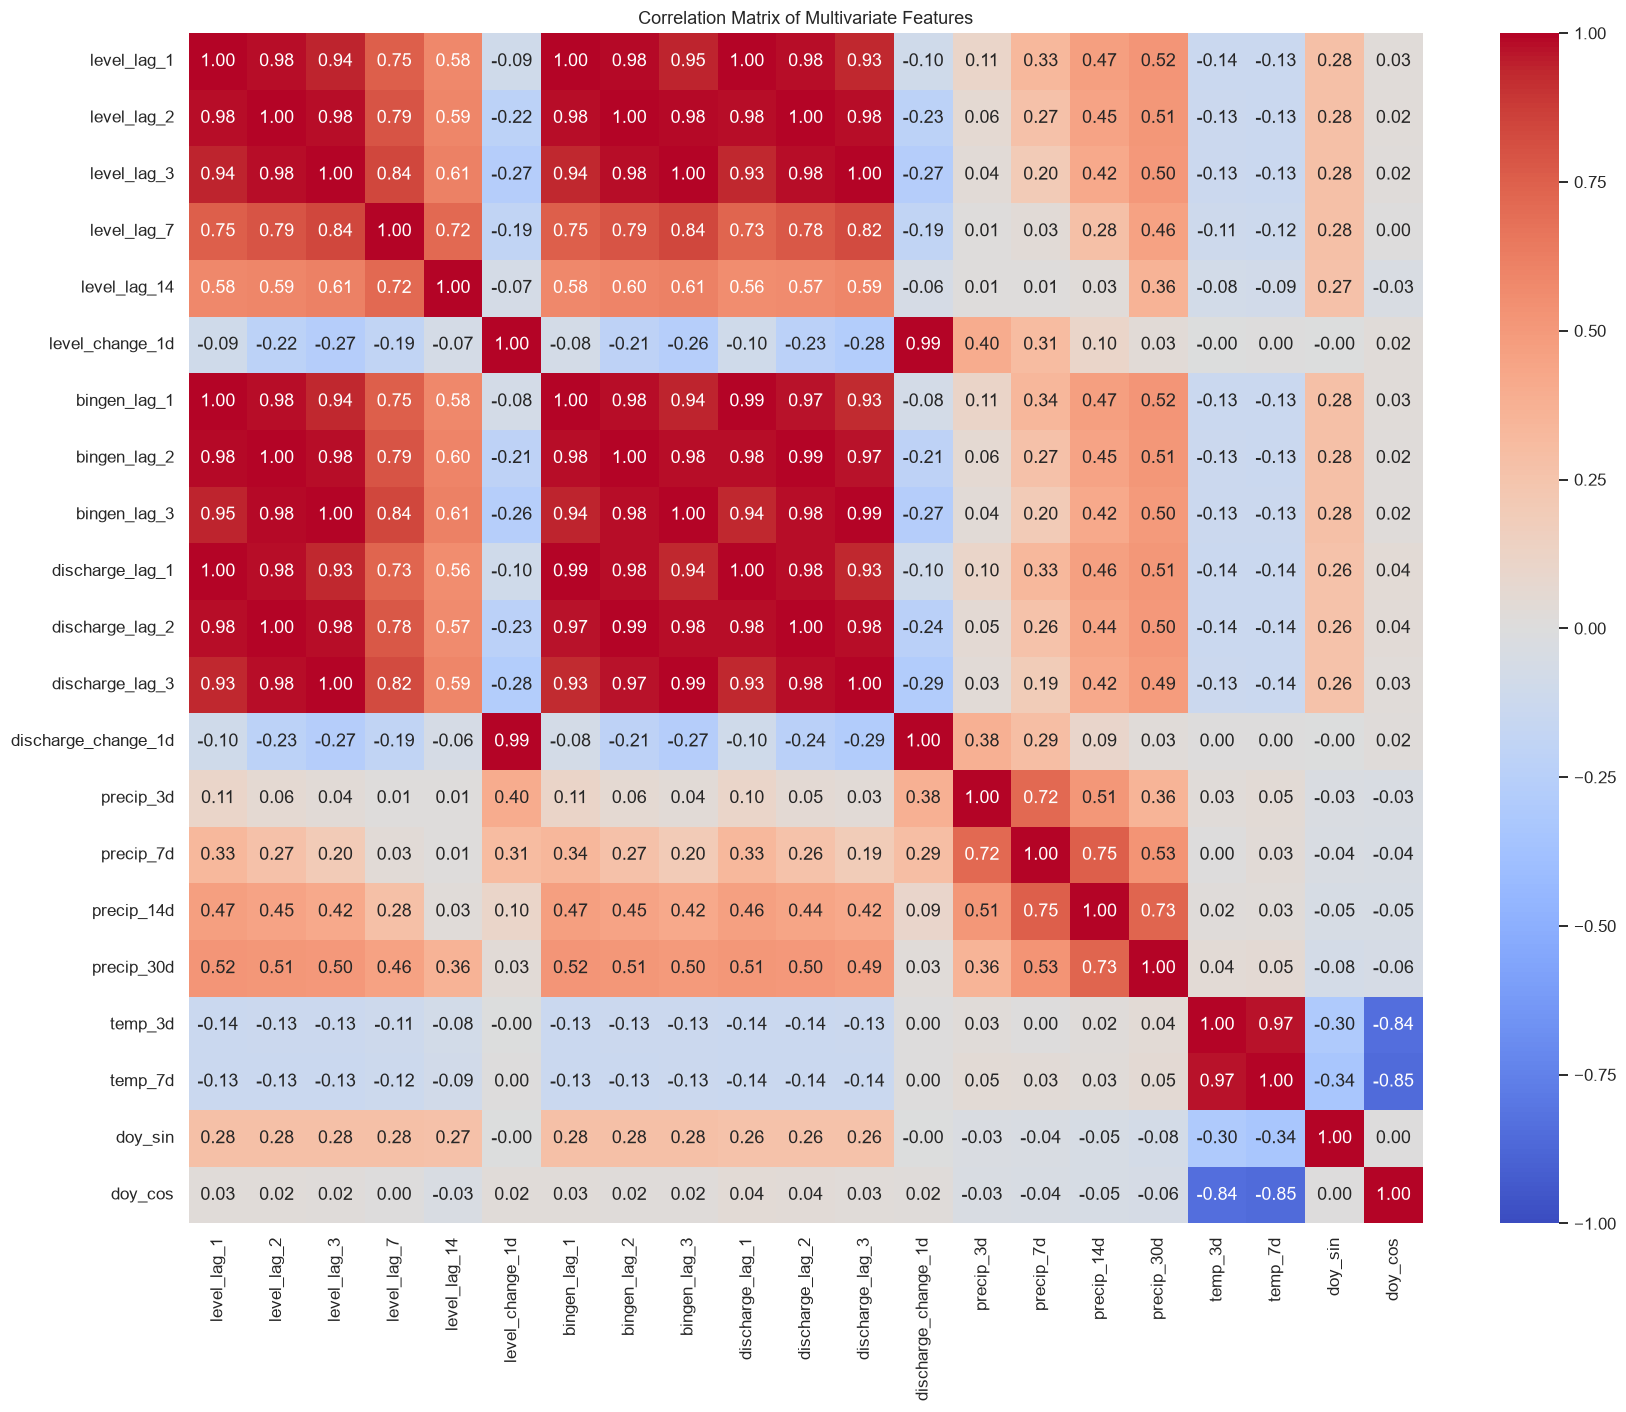

In [29]:
# Heatmap : Correlation between engineered features
feature_corr = df[FEATURES].corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Correlation Matrix of Multivariate Features"
)

plt.tight_layout()
plt.show()

In [30]:
model_df = df[
    ["date"] + FEATURES + TARGETS
].dropna().copy()

print(model_df.shape)
print(model_df["date"].min())
print(model_df["date"].max())

(9705, 29)
2000-01-30 00:00:00
2026-08-25 00:00:00


In [31]:
# Print features
print("FEATURES:", FEATURES)

print("\nAvailable columns:")
print(df.columns.tolist())

print("\nMissing features:")
print([col for col in FEATURES if col not in df.columns])

FEATURES: ['level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'temp_3d', 'temp_7d', 'doy_sin', 'doy_cos']

Available columns:
['date', 'water_level_mean', 'water_level_min', 'water_level_max', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'pressure_mean', 'wind_speed_mean', 'bingen_level_mean', 'bingen_level_min', 'bingen_level_max', 'discharge_mean', 'discharge_min', 'discharge_max', 'hours_available', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'temp_3d', 'temp_7d', 'day_of_year', 'doy_sin', 'd

In [32]:
# Kaub water level lag features
LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

for lag in LAGS:
    df[f"lag_{lag}"] = (
        df["water_level_mean"].shift(lag)
    )

In [33]:
# Seven-day forecasting targets
TARGETS = []

for h in range(1, 8):

    target_col = f"target_day_{h}"

    df[target_col] = (
        df["water_level_mean"].shift(-h)
    )

    TARGETS.append(target_col)

In [34]:
# Check whether all required columns exist
missing_cols = [
    col for col in FEATURES + TARGETS
    if col not in df.columns
]

if missing_cols:
    print("Missing columns:", missing_cols)

else:
    # Calculate correlations
    corr_horizons = (
        df[FEATURES + TARGETS]
        .corr()
        .loc[FEATURES, TARGETS]
    )

    display(corr_horizons.round(3))

,target_day_1,target_day_2,target_day_3,target_day_4,target_day_5,target_day_6,target_day_7
level_lag_1,0.941,0.890,0.840,0.794,0.753,0.716,0.684
level_lag_2,0.890,0.840,0.794,0.753,0.716,0.684,0.655
level_lag_3,0.840,0.794,0.753,0.716,0.684,0.655,0.631
level_lag_7,0.684,0.655,0.631,0.611,0.594,0.580,0.567
level_lag_14,0.555,0.544,0.533,0.523,0.514,0.505,0.494
level_change_1d,0.223,0.269,0.267,0.244,0.218,0.194,0.173
bingen_lag_1,0.945,0.895,0.846,0.800,0.759,0.722,0.690
bingen_lag_2,0.895,0.846,0.800,0.759,0.722,0.690,0.661
bingen_lag_3,0.846,0.800,0.759,0.722,0.690,0.661,0.636
discharge_lag_1,0.934,0.881,0.829,0.782,0.740,0.702,0.669


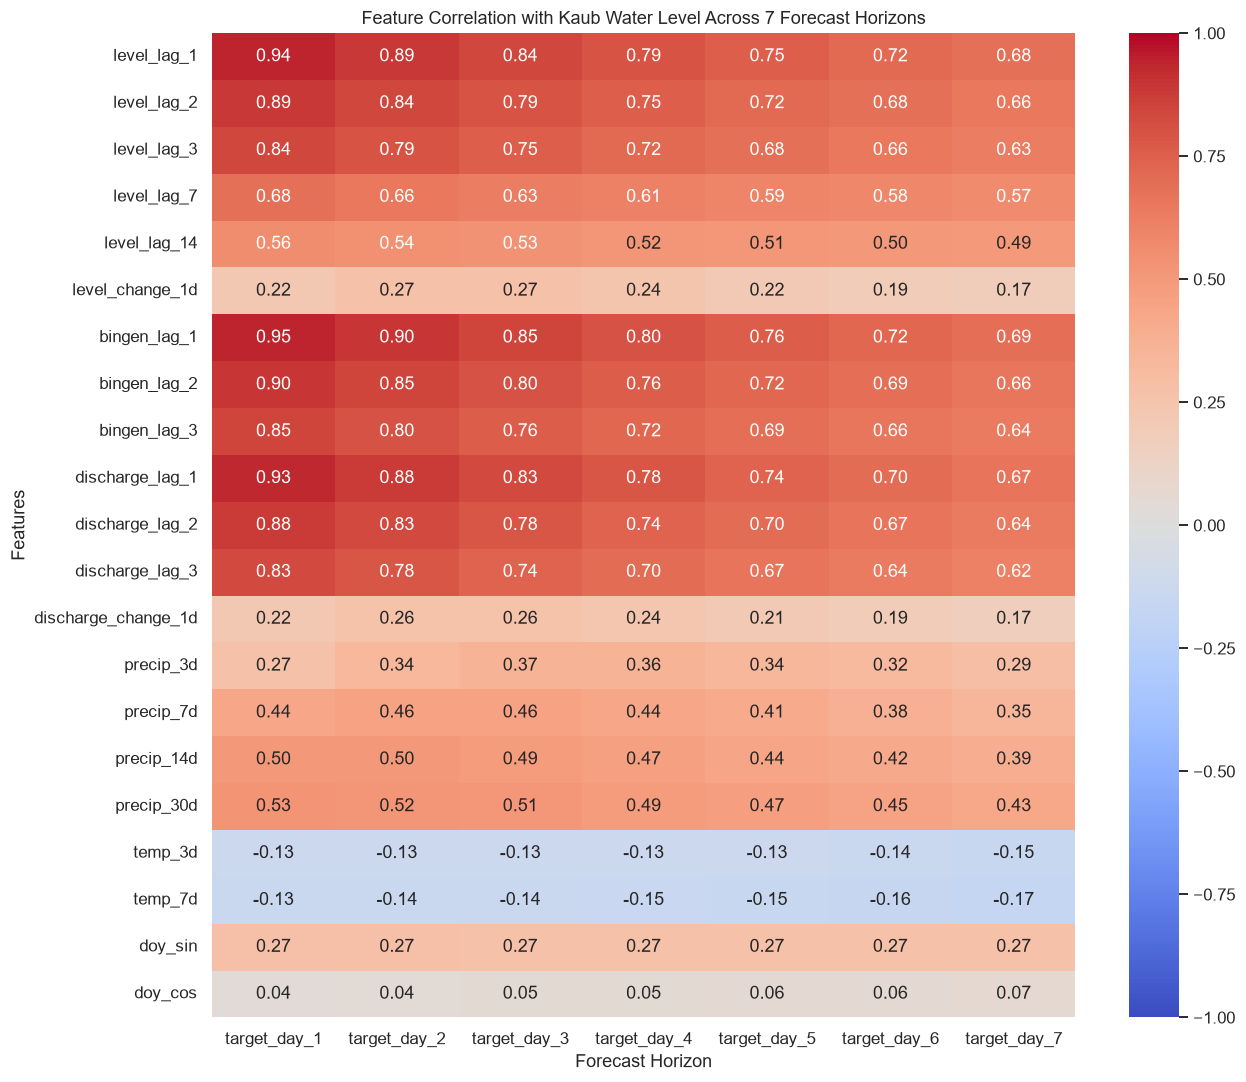

In [35]:
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_horizons,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title(
    "Feature Correlation with Kaub Water Level "
    "Across 7 Forecast Horizons"
)

plt.xlabel("Forecast Horizon")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [36]:
# Prepare the univariate time-series dataset using historical Kaub water levels
# Create lag features and a target variable for forecasting water levels 7 days ahead

HORIZON = 7
H = HORIZON

LAGS = [0, 1, 2, 3, 4, 5, 6, 7, 14, 21, 28]

# Select Kaub daily mean water level
s = df["water_level_mean"]

data = pd.DataFrame(index=s.index)

for L in LAGS:
    data[f"lag_{L}"] = s.shift(L)

data["target"] = s.shift(-H)

FEATURES = [f"lag_{L}" for L in LAGS]

data.head(35)

,lag_0,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_14,lag_21,lag_28,target
0,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,305
1,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,294
2,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,285
3,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,282
4,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,284
5,311,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,<NA>,272
6,304,311,328,346,368,401,439,<NA>,<NA>,<NA>,<NA>,260
7,305,304,311,328,346,368,401,439,<NA>,<NA>,<NA>,250
8,294,305,304,311,328,346,368,401,<NA>,<NA>,<NA>,238
9,285,294,305,304,311,328,346,368,<NA>,<NA>,<NA>,226


In [37]:
# Validate the alignment of lag features and the 7-day-ahead target
# Confirm that the current water level and future target correspond to the correct dates

i = 400

row = data.iloc[i]

assert row["lag_0"] == s.iloc[i]

assert row["target"] == s.iloc[i + H]

print(
    f"On {data.index[i]}: "
    f"today={row['lag_0']:.2f}, "
    f"target(+{H}d)={row['target']:.2f}"
)

On 400: today=230.00, target(+7d)=308.00


In [38]:
# Check the index type and values to verify the time-series date index

print(type(data.index))

print(data.index)

<class 'pandas.RangeIndex'>
RangeIndex(start=0, stop=9741, step=1)


In [39]:
# Set the date as a sorted datetime index for time-series analysis
# Select the daily mean Kaub water level as the target series

df["date"] = pd.to_datetime(df["date"])

df = df.set_index("date").sort_index()

s = df["water_level_mean"]

In [40]:
# Define the forecast horizon and test period, then verify the dataset structure
# Check the date index, input features, data dimensions, and target availability

H = 7

TEST_YEARS = 3

print("Index type:", type(data.index))

print("Features:", FEATURES)

print("Data shape:", data.shape)

print("Target exists:", "target" in data.columns)

print("First date:", data.index.min())

print("Last date:", data.index.max())

Index type: <class 'pandas.RangeIndex'>
Features: ['lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28']
Data shape: (9741, 12)
Target exists: True
First date: 0
Last date: 9740


In [41]:
print(df.columns.tolist())
print(df.head(3))

['water_level_mean', 'water_level_min', 'water_level_max', 'temperature_mean', 'humidity_mean', 'precipitation_sum', 'rain_sum', 'snowfall_sum', 'pressure_mean', 'wind_speed_mean', 'bingen_level_mean', 'bingen_level_min', 'bingen_level_max', 'discharge_mean', 'discharge_min', 'discharge_max', 'hours_available', 'precip_3d', 'precip_7d', 'precip_14d', 'precip_30d', 'level_lag_1', 'level_lag_2', 'level_lag_3', 'level_lag_7', 'level_lag_14', 'level_change_1d', 'bingen_lag_1', 'bingen_lag_2', 'bingen_lag_3', 'discharge_lag_1', 'discharge_lag_2', 'discharge_lag_3', 'discharge_change_1d', 'temp_3d', 'temp_7d', 'day_of_year', 'doy_sin', 'doy_cos', 'target_day_1', 'target_day_2', 'target_day_3', 'target_day_4', 'target_day_5', 'target_day_6', 'target_day_7', 'lag_0', 'lag_1', 'lag_2', 'lag_3', 'lag_4', 'lag_5', 'lag_6', 'lag_7', 'lag_14', 'lag_21', 'lag_28']
            water_level_mean  water_level_min  water_level_max  temperature_mean  humidity_mean  precipitation_sum  rain_sum  \
date     

In [42]:
print(type(df.index))

<class 'pandas.DatetimeIndex'>


In [43]:
df.index = pd.to_datetime(df.index)
df = df.sort_index()

In [44]:
# Prepare the multivariate dataset with a datetime index and selected input features
# Set the 7-day-ahead water level as the target and verify the dataset structure

import pandas as pd

df.index = pd.to_datetime(df.index)
df = df.sort_index()

FEATURES = [
    "lag_0", "lag_1", "lag_2", "lag_3",
    "lag_7", "lag_14", "lag_28",
    "precip_3d", "precip_7d", "precip_14d", "precip_30d",
    "temp_3d", "temp_7d",
    "bingen_lag_1", "bingen_lag_2", "bingen_lag_3",
    "doy_sin", "doy_cos"
]

data = df[FEATURES + ["target_day_7"]].copy()
data = data.rename(columns={"target_day_7": "target"})

print("df index:", type(df.index))
print("data index:", type(data.index))
print("Last date:", data.index.max())

df index: <class 'pandas.DatetimeIndex'>
data index: <class 'pandas.DatetimeIndex'>
Last date: 2026-09-01 00:00:00


In [45]:
# Split the time-series data into training and test sets using the last 3 years for testing
# Apply a 7-day embargo to prevent overlapping forecast targets and verify temporal separation

H = 7

TEST_YEARS = 3

split_date = data.index.max() - pd.DateOffset(years=TEST_YEARS)

train = data.loc[:split_date - pd.Timedelta(days=H)].dropna()

test = data.loc[split_date + pd.Timedelta(days=1):].dropna()

X_train, y_train = train[FEATURES], train["target"]

X_test, y_test = test[FEATURES], test["target"]

print(f"train: {train.index.min().date()} → {train.index.max().date()} n={len(train)}")

print(f"test : {test.index.min().date()} → {test.index.max().date()} n={len(test)}")

assert train.index.max() + pd.Timedelta(days=H) < test.index.min(), "embargo violated"

train: 2000-01-30 → 2023-08-25 n=8609
test : 2023-09-02 → 2026-08-25 n=1089


In [46]:
# Split the training data into model-fitting and validation sets, using the last 2 years for validation
# Apply a 7-day embargo to prevent target overlap and ensure temporal separation

VALID_YEARS = 2

validation_start = (
    train.index.max() - pd.DateOffset(years=VALID_YEARS)
    + pd.Timedelta(days=1)
)

train_fit = train.loc[
    :validation_start - pd.Timedelta(days=H + 1)
].copy()

validation = train.loc[
    validation_start:
].copy()

print(
    f"Model fitting: {train_fit.index.min().date()} → "
    f"{train_fit.index.max().date()} | n={len(train_fit)}"
)

print(
    f"Validation:    {validation.index.min().date()} → "
    f"{validation.index.max().date()} | n={len(validation)}"
)

assert (
    train_fit.index.max() + pd.Timedelta(days=H)
    < validation.index.min()
), "Validation embargo violated"

Model fitting: 2000-01-30 → 2021-08-18 | n=7872
Validation:    2021-08-26 → 2023-08-25 | n=730


In [51]:
# Define feature groups to evaluate the contribution of additional weather and hydrological variables
# Compare different feature combinations to identify which inputs improve water-level forecasting

feature_groups = {
    "Kaub only": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28"
    ],

    "Kaub + precipitation": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28",
        "precip_3d", "precip_7d",
        "precip_14d", "precip_30d"
    ],

    "Kaub + precipitation + temperature": [
        "lag_0", "lag_1", "lag_2", "lag_3",
        "lag_7", "lag_14", "lag_28",
        "precip_3d", "precip_7d",
        "precip_14d", "precip_30d",
        "temp_3d", "temp_7d"
    ],

     #"Kaub + weather + Bingen + discharge": [
      #  "lag_0", "lag_1", "lag_2", "lag_3",
       # "lag_7", "lag_14", "lag_28",

        # Precipitation
        #"precip_3d", "precip_7d",
        #"precip_14d", "precip_30d",

        # Temperature
        #"temp_3d", "temp_7d",

        # Bingen water level
        #"bingen_lag_1", "bingen_lag_2",
        #"bingen_lag_3", "bingen_lag_7",

        # Kaub discharge
        #"discharge_lag_1", "discharge_lag_3",
        #"discharge_lag_7", "discharge_7d_mean"
    #],

    "All selected features": FEATURES
}

In [52]:
# Train and evaluate Linear Regression models using different feature groups
# Compare validation MAE and RMSE to assess the impact of additional features on forecasting accuracy

import pandas as pd #
from sklearn.linear_model import LinearRegression 
from sklearn.metrics import mean_absolute_error, mean_squared_error

results = []

for group_name, columns in feature_groups.items():

    model = LinearRegression()

    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    predictions = model.predict(validation[columns])

    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = mean_squared_error(
        validation["target"],
        predictions
    ) ** 0.5

    results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse
    })

results_df = pd.DataFrame(results)

display(results_df.round(2))

,Feature group,Number of features,MAE,RMSE
0,Kaub only,7,45.45,57.38
1,Kaub + precipitation,11,46.28,58.29
2,Kaub + precipitation + temperature,13,45.17,56.57
3,All selected features,18,45.00,57.26


In [53]:
# Evaluate the persistence baseline by assuming the water level remains unchanged after 7 days
# Calculate MAE and RMSE to compare baseline performance with the machine learning models

persistence_predictions = validation["lag_0"]

persistence_mae = mean_absolute_error(
    validation["target"],
    persistence_predictions
)

persistence_rmse = mean_squared_error(
    validation["target"],
    persistence_predictions
) ** 0.5

print(f"Persistence MAE:  {persistence_mae:.2f} cm")

print(f"Persistence RMSE: {persistence_rmse:.2f} cm")

Persistence MAE:  45.24 cm
Persistence RMSE: 64.23 cm


In [54]:
# Calculate the relative improvement in MAE compared with the persistence baseline
# Positive skill indicates better forecasting performance than persistence

results_df["Skill vs persistence"] = (
    1 - results_df["MAE"] / persistence_mae
)

display(results_df.round(3))

,Feature group,Number of features,MAE,RMSE,Skill vs persistence
0,Kaub only,7,45.446,57.376,-0.005
1,Kaub + precipitation,11,46.275,58.294,-0.023
2,Kaub + precipitation + temperature,13,45.169,56.572,0.002
3,All selected features,18,45.000,57.263,0.005


In [55]:
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import pandas as pd
import numpy as np

# Train and evaluate XGBoost models using different feature groups
# Compare MAE, RMSE, R², Bias, and skill against the persistence baseline

xgb_results = []
xgb_models = {}

for group_name, columns in feature_groups.items():

    model = XGBRegressor(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=4,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    predictions = model.predict(validation[columns])

    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = mean_squared_error(
        validation["target"],
        predictions
    ) ** 0.5

    R2 = r2_score(
        validation["target"],
        predictions
    )

    bias = np.mean(
        predictions - validation["target"]
    )

    xgb_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_square": R2,
        "Bias": bias,
        "Skill vs persistence": 1 - mae / persistence_mae
    })

    xgb_models[group_name] = model

xgb_results_df = pd.DataFrame(xgb_results)

display(xgb_results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R_square,Bias,Skill vs persistence
0,Kaub only,7,46.464,59.838,0.357,10.453,-0.027
1,Kaub + precipitation,11,45.549,59.888,0.356,11.162,-0.007
2,Kaub + precipitation + temperature,13,43.697,56.109,0.435,11.970,0.034
3,All selected features,18,44.624,57.192,0.413,15.093,0.014


In [56]:
linear_comparison = results_df.copy()
linear_comparison["Model"] = "Linear Regression"

xgb_comparison = xgb_results_df.copy()
xgb_comparison["Model"] = "XGBoost"

comparison = pd.concat(
    [linear_comparison, xgb_comparison],
    ignore_index=True
)

comparison = comparison[
    [
        "Model",
        "Feature group",
        "Number of features",
        "MAE",
        "RMSE",
        "Skill vs persistence"
    ]
]

display(comparison.round(3))

,Model,Feature group,Number of features,MAE,RMSE,Skill vs persistence
0,Linear Regression,Kaub only,7,45.446,57.376,-0.005
1,Linear Regression,Kaub + precipitation,11,46.275,58.294,-0.023
2,Linear Regression,Kaub + precipitation + temperature,13,45.169,56.572,0.002
3,Linear Regression,All selected features,18,45.000,57.263,0.005
4,XGBoost,Kaub only,7,46.464,59.838,-0.027
5,XGBoost,Kaub + precipitation,11,45.549,59.888,-0.007
6,XGBoost,Kaub + precipitation + temperature,13,43.697,56.109,0.034
7,XGBoost,All selected features,18,44.624,57.192,0.014


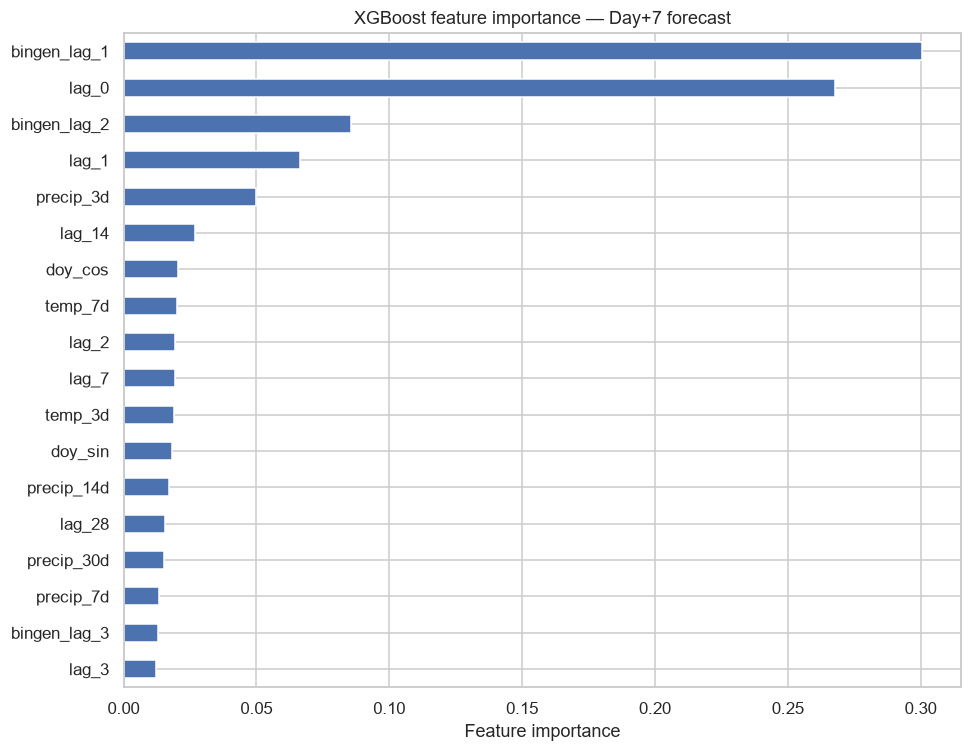

In [57]:

model = xgb_models["All selected features"]

importance = pd.Series(
    model.feature_importances_,
    index=feature_groups["All selected features"]
).sort_values()

importance.plot(
    kind="barh",
    figsize=(9, 7),
    title="XGBoost feature importance — Day+7 forecast"
)

plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [67]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import numpy as np

In [80]:
# Store results and trained models
lgbm_results = []
lgbm_models = {}

# Loop through each feature group
for group_name, columns in feature_groups.items():

    # Initialize LightGBM model
    model = LGBMRegressor(
        n_estimators=500,
        learning_rate=0.05,
        max_depth=4,
        num_leaves=15,
        min_child_samples=20,
        subsample=0.8,
        subsample_freq=1,
        colsample_bytree=0.8,
        reg_alpha=0.2,
        reg_lambda=1.0,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # Train model
    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    # Predict on validation data
    predictions = model.predict(
        validation[columns]
    )

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["target"],
            predictions
        )
    )

    R2 = r2_score(
        validation["target"],
        predictions
    )

    # Calculate skill vs persistence
    skill = 1 - mae / persistence_mae

    # Store results
    lgbm_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": R2,
        "Skill vs persistence": skill
    })

    # Store trained model
    lgbm_models[group_name] = model

# Create results DataFrame
lgbm_results_df = pd.DataFrame(lgbm_results)

# Display results
display(lgbm_results_df.round(3))

,Feature group,Number of features,MAE,RMSE,R_squared,Skill vs persistence
0,Kaub only,7,46.232,60.017,0.353,-0.022
1,Kaub + precipitation,11,44.881,59.059,0.374,0.008
2,Kaub + precipitation + temperature,13,43.914,56.723,0.422,0.029
3,All selected features,18,45.234,58.256,0.391,0.000


MOdeling : TAB ICL

In [81]:

from tabicl import TabICLRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

c:\Users\Prithvi Hegde\neuefische_course\Rhine-cargo-advisor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [82]:
# Store results and trained models
tabicl_results = []
tabicl_models = {}

# Loop through each feature group
for group_name, columns in feature_groups.items():

    print(f"Training TabICL: {group_name}")

    # Initialize TabICL model
    model = TabICLRegressor(
        n_estimators=8,
        random_state=42
    )

    # Train model
    model.fit(
        train_fit[columns],
        train_fit["target"]
    )

    # Predict on validation data
    predictions = model.predict(
        validation[columns]
    )

    # Calculate evaluation metrics
    mae = mean_absolute_error(
        validation["target"],
        predictions
    )

    rmse = np.sqrt(
        mean_squared_error(
            validation["target"],
            predictions
        )
    )

    R2 = r2_score(
        validation["target"],
        predictions
    )

    # Calculate skill vs persistence
    skill = 1 - mae / persistence_mae

    # Store results
    tabicl_results.append({
        "Feature group": group_name,
        "Number of features": len(columns),
        "MAE": mae,
        "RMSE": rmse,
        "R_squared": R2,
        "Skill vs persistence": skill
    })

    # Store trained model
    tabicl_models[group_name] = model

# Create results DataFrame
tabicl_results_df = pd.DataFrame(tabicl_results)

# Display results
display(tabicl_results_df.round(3))

Training TabICL: Kaub only
Training TabICL: Kaub + precipitation
Training TabICL: Kaub + precipitation + temperature
Training TabICL: All selected features


,Feature group,Number of features,MAE,RMSE,R_squared,Skill vs persistence
0,Kaub only,7,43.799,56.945,0.418,0.032
1,Kaub + precipitation,11,44.261,59.166,0.371,0.022
2,Kaub + precipitation + temperature,13,46.942,62.093,0.308,-0.038
3,All selected features,18,52.782,69.209,0.140,-0.167
